# Monthly Road-Segment Accident Prediction with Graph Neural Networks

## Introduction

Road traffic accidents impose substantial human and economic costs, estimated to cost an average of 2.7% of GDP in high-income countries (Wijnen & Stipdonk, 2016). They can be caused by pedestrians, drivers, vehicles, or the road environments. Although human behaviour is an important factor in crashes, road environments may also contribute by influencing the likelihood of driver errors and violations (Ahmad et al., 2021). Differences in road layout, traffic volume, surrounding land use and environmental conditions can contribute to differences in where crashes occur. Understanding the relationship between road characteristics and accidents may therefore help transport agencies identify road segments with elevated accident risk and prioritise them for safety assessment and improvements.

Machine learning offers a way to combine information about roads and their surroundings to predict where accidents are more likely to occur. Relevant information may include historical accident records, traffic volume and road characteristics. However, roads do not exist in isolation: connected road segments may share traffic flows, infrastructure and environmental conditions. This suggests that the relationships between roads may provide useful information for accident prediction. Graph-based methods provide a way to account for these connections when predicting accidents.

### Objectives

This project uses the ML4RoadSafety benchmark to study monthly accident prediction on road networks (Nippani et al., 2023). It aims to assess how well models predict monthly accidents on physical roads and whether additional information like network structure, additional road context, and previous accident records can improve those predictions.

### Research questions
> [!NOTE]
> Need to rewrite once the report is confirmed

1. **Network representation and learning:** How does the use of different graph machine learning methods improve the prediction of road traffic accident predictions?
2. **Road features and history**: To what extent do richer road characteristics and historical accident information improve monthly road-level accident prediction?

### Main contributions
> [!NOTE]
> Need to rewrite once the report is confirmed

- We compare an MLP and edge-aware GraphSAGE, with and without Node2Vec, under a shared physical-road target and chronological evaluation protocol.
- We develop an OSM enrichment and matching pipeline, audit its coverage, and assess its predictive value and feature reliance for GraphSAGE classification.
- We construct a past-only accident history representation and examine training-period evidence of temporal persistence, complemented by interactive spatial exploration.

These experiments adapt the benchmark's features, embeddings and target aggregation, so the reported scores constitute a modified reproduction rather than direct replications of the published results.


## Related Work

### Road Accidents Predictions

Existing work have explored the use of various methods to predict road accidents, ranging from statistical models, machine learning models, and deep learning models. Statistical learning approaches relate expected accident counts to road and traffic characteristics using count regression. Ma et al. (2017) applied negative-binomial and random-effects negative-binomial models to predict crash frequency on segments of a Chinese expressway using explanatory variables such as road geometry, and also explored the spatial and temporal correlation in the accidents data.

Traditional machine-learning approaches use algorithms like random forest and support vector machines to predict crashes (Guerra et al., 2022). Guerra et al. compared linear regression, Generalised Additve models, random forest, support vector machines, and artificial neural network on the traffic prediction task. They found that random forests produced the best results and the traffic volume given by annual average daily traffic (AADT), was a significant variable in predicting the crashes.

Deep-learning approaches can learn richer representations from information about roads to predict traffic accidents. Kashifi et al. (2023) developed a hybrid model combining convolutional neural networks, LSTMs and artificial neural networks for short-term crash prediction. They used information such as average speed, vehicle occupancy, weather data, temporal information, and crash data from the Paris road network, combining multiple different information to predict road traffic accidents.

Graph-based approaches are well suited for road accident prediction because roads form an interconnected network, and conditions on one road may be related to those on neighbouring roads. Graph models can represent these relationships explicitly and aggregate information between related road segments to improve predictions. Huang and Hooi (2022) developed TRAVEL, a graph neural network that incorporates road geometry and connectivity to predict accident occurrence and severity at intersections. Their model achieved better overall F1 and AUC scores than non-graph XGBoost and MLP baselines on their city datasets. Furthermore, their experiments also used other graph neural network (GNN) models such as Graph Convolutional Network (GCN), GraphSAGE, and ChebNet, which achieved better scores compared to the non-graph methods, supporting the argument that graph methods are well suited for road accident prediction tasks.

### Graph representation learning

Graph representation learning provides a framework for incorporating road-network structure into accident prediction. A road network can be represented as a graph whose nodes denote intersections and whose edges denote road segments. This representation allows a model to combine the attributes of a location with information from its connected roads and neighbouring intersections. Several methods differ in how they encode this structure and determine the contribution of neighbouring locations.

Node2Vec is a form of shallow graph learning that learns a vector representation for each node in the graph, which can be used for downstream predictive tasks (Grover & Leskovec, 2016). It is adapted from word2vec (Mikolov et al., 2013), where words are represented by nodes, while sentences are represented by biased random walk sequences along the graph. The biased random walk is obtained through a sampling process, controlled by two parameters, $p$ and $q$, which controls the probability of moving back to the previous node, and controls the probability of local or outward exploration. This provides more flexibility to the representation it can capture. Furthermore, it uses a skip-gram objective function, which helps to encourage nodes that are in the same random walk, and therefore likely to be close to one another, to have similar embeddings.

GraphSAGE learns node representations by performing uniform sampling around the node's neighbourhood, followed by aggregating features of the sampled nodes (Hamilton et al., 2017). Some examples of aggregation include using the mean, maximum, or using a Long Short Term Memory (LSTM) (Hochreiter & Schmidhuber, 1997). A non-linear transformation is applied to the concatenation of the node's features and its sampled neighbourhood, through multiple layers of aggregation. The multiple layers of aggregation helps to incorporate information from increasingly distant neighbours, allowing a node to capture more context and information beyond its neighbourhood.

However, GraphSAGE is an isotropic GNN. This means that the neighbours have no canonical direction labels and the different edges all same the same magnitude and weight regardless of their importance. GatedGCN (Bresson & Laurent, 2017) and Graph Transformers (Dwivedi & Bresson, 2020) are anisotropic GNNs which allow the contribution of neighbouring nodes to vary. GatedGCN uses learnable edge gates to control the contribution of neighbouring nodes during aggregation. The gates are learned from node and edge representations, allowing the model to adjust messages according to the relationship between connected nodes. Since the edge representations will get updated, GatedGCN can perform edge-aware message passing, which helps to improve tasks requiring edge predictions.

Graph Transformers (Dwivedi & Bresson, 2020) extend Transformers (Vaswani et al., 2017) to the graph domain by using the attention mechanism to assign weights to neighbouring nodes, restricting how nodes access and share information with one another. The attention mechanism assigns weights to these neighbours based on their representations, allowing their contributions to vary during aggregation. It also incorporates edge features into the attention mechanism, allowing attributes of the connections between nodes to influence the learned representations. In addition, Laplacian eigenvectors are used as node positional encoding to inject structural information to increase the expressivity of the models.

## Dataset and Exploratory Analysis

### Dataset, graph representation and prediction tasks

ML4RoadSafety is a public road-safety dataset constructed from official accident reports across eight US states, comprising more than nine million records in the full collection (Nippani et al., 2023). It links accident locations and dates to road networks derived from OpenStreetMap (OSM). Each state is represented as a directed graph, where nodes correspond to intersections and edges represent road segments. The dataset includes node-level structural and weather information, such as node degree, betweenness centrality, temperature and precipitation, as well as edge-level attributes, including road length, road category and AADT, where available. Accident records are associated with road-network edges and can be used to study monthly accident counts and occurrence. The dataset is available through [Harvard Dataverse](https://doi.org/10.7910/DVN/V71K5R). This study uses Delaware and Maryland for descriptive analysis and Delaware for predictive experiments; the full-collection accident total does not describe this subset.

For prediction, this study groups directed edges with the same unordered endpoints into a single **physical-road proxy**, summing their accident counts for each month. The original benchmark instead defines its prediction task at the directed-edge level (Nippani et al., 2023). Our message-passing graph remains directed. A **road-month** is one physical-road proxy observed in one month: classification predicts whether its count exceeds zero, while regression estimates the count. Zero-count roads are included in the target population. Endpoint-based grouping does not establish that every grouped pair is the same physical road and does not support direction-specific conclusions.

Our feature construction, structural embedding implementation, physical-road aggregation and evaluation population adapt the original benchmark. These methodological changes make the experiments a modified reproduction, so their scores are not direct replications of the published benchmark results.


In [1]:
# Use Google Drive in Colab, or the local repository otherwise.
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/gdrive')
    # Set this to the repository folder containing src/ and data/ in Drive.
    PROJECT_DIR = Path(os.environ.get(
        'CS5284_PROJECT_DIR', '/content/gdrive/MyDrive/cs5284_project'))
else:
    configured = os.environ.get('CS5284_PROJECT_DIR')
    if configured:
        PROJECT_DIR = Path(configured).expanduser()
    else:
        PROJECT_DIR = next(
            (p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src' / 'eda.py').is_file()), None)
        if PROJECT_DIR is None:
            raise FileNotFoundError('Open this notebook inside the repository or set CS5284_PROJECT_DIR.')

PROJECT_DIR = PROJECT_DIR.resolve()
if not (PROJECT_DIR / 'src' / 'eda.py').is_file():
    raise FileNotFoundError(f'Place the repository (including src/eda.py) in {PROJECT_DIR}, or update PROJECT_DIR.')
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
DATA_DIR = Path(os.environ.get('CS5284_DATA_DIR', str(PROJECT_DIR / 'data'))).expanduser().resolve()
os.environ['CS5284_PROJECT_DIR'] = str(PROJECT_DIR)
os.environ['CS5284_DATA_DIR'] = str(DATA_DIR)
print(f'Project: {PROJECT_DIR}')
print(f'Data: {DATA_DIR}')


In [2]:
from IPython.display import display
import matplotlib.pyplot as plt
from src.reporting import apply_report_style
apply_report_style()
from src.eda import (
    load_data, dataset_summary, split_summary, audit_data,
    accident_distribution, concentration, historical_persistence,
    plot_monthly_accidents, plot_risk_profile,
)

# Select ('DE',) for a Delaware-only run. Data must already be extracted.
STATES = ('DE', 'MD')
data = load_data(DATA_DIR, states=STATES)
summary = dataset_summary(data)
audit = audit_data(data)  # Streams node CSVs once; reused below.
distribution = accident_distribution(data)
concentration_table = concentration(data)


In [3]:
display(summary[['Period', 'Nodes', 'Directed edges', 'Physical roads',
                 'Accidents/month', 'Traffic coverage (%)']].style.format({
    'Nodes': '{:,.0f}', 'Directed edges': '{:,.0f}', 'Physical roads': '{:,.0f}',
    'Accidents/month': '{:,.0f}', 'Traffic coverage (%)': '{:.2f}',
}).set_caption('Table 1. Dataset scope; traffic coverage is the share of physical roads with a finite AADT observation in any supplied year.'))


,Period,Nodes,Directed edges,Physical roads,Accidents/month,Traffic coverage (%)
State,,,,,,
Delaware,2009-01 to 2022-09,"49,023","116,196","65,252","2,777",3.16
Maryland,2015-01 to 2022-12,"250,565","580,526","317,281","9,149",1.40


### Data quality and chronological coverage

Delaware covers January 2009–September 2022 (165 months), while Maryland covers January 2015–December 2022 (96 months). October 2022 is excluded for Delaware because monthly node features are unavailable and the month is treated as incomplete.

Data checks cover label validity, duplicate directed road-month records, graph membership, node ordering, feature dimensions and missing observations. The audit identifies no duplicate accident records or invalid counts, and all accident records map to graph edges. Roads with missing attributes are retained. Monthly weather and traffic are imputed and standardised using training-year statistics, with missingness indicators; traffic observations are carried forward only from earlier years. Static-graph scaling is described separately in Methodology.

The chronological splits follow Nippani et al. (2023). Full-period plots describe temporal coverage and distributional changes; neighbour-risk and history associations use training years. This distinction prevents descriptive use of the full period from being interpreted as held-out predictive evidence. Forecast evaluation requires inputs to respect the information available before each target observation (Hyndman & Athanasopoulos, 2021, Section 5.10).


In [4]:
display(split_summary(data).style.set_caption('Table 2. Chronological splits and observed month availability.'))

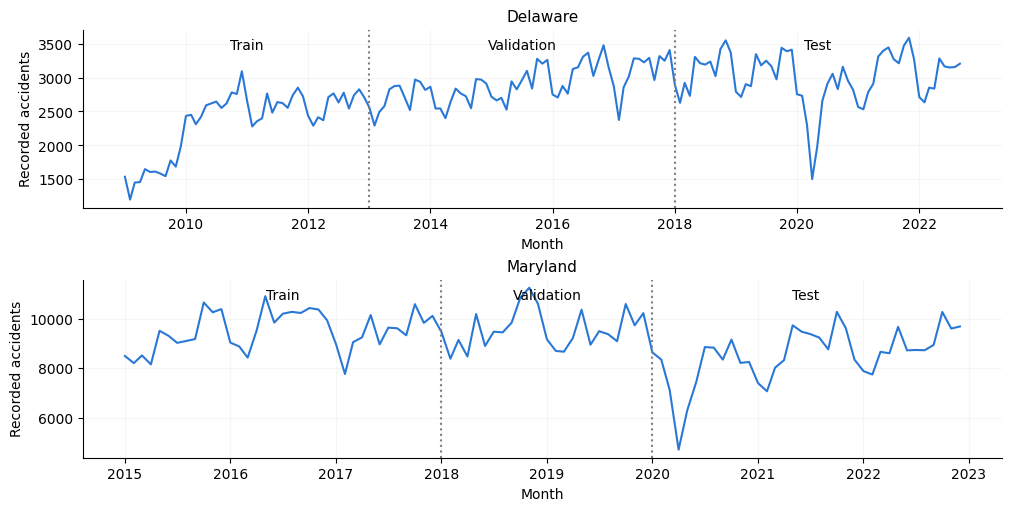

In [5]:
fig = plot_monthly_accidents(data)
plt.show()


*Figure 1. Monthly recorded accidents and chronological split boundaries.* Both states show a decline around early 2020 followed by recovery. The timing coincides with the national decline in road travel reported by the Federal Highway Administration (2021), although this correspondence does not identify the cause of the state-level changes. The decline falls within the test period and illustrates temporal distribution shift.

### Accident sparsity and concentration

Zero-count road-months account for **96.52%** of Delaware's population and **97.61%** of Maryland's. Consequently, low MAE alone can favour predictions near zero. Precision-recall evaluation complements AUROC by focusing on the rare positive class (Saito & Rehmsmeier, 2015), while top-risk metrics assess prioritisation.

The highest-count 10% of roads account retrospectively for **70.6%** and **73.6%** of accidents, respectively. This concentration motivates road-level prioritisation. Because the ranking uses observed counts across the full period, it describes concentration rather than forecast performance.


,Road-months,Zero accidents (%),Mean count
State,,,
Delaware,"10,766,580",96.52,0.0426
Maryland,"30,458,976",97.61,0.0288


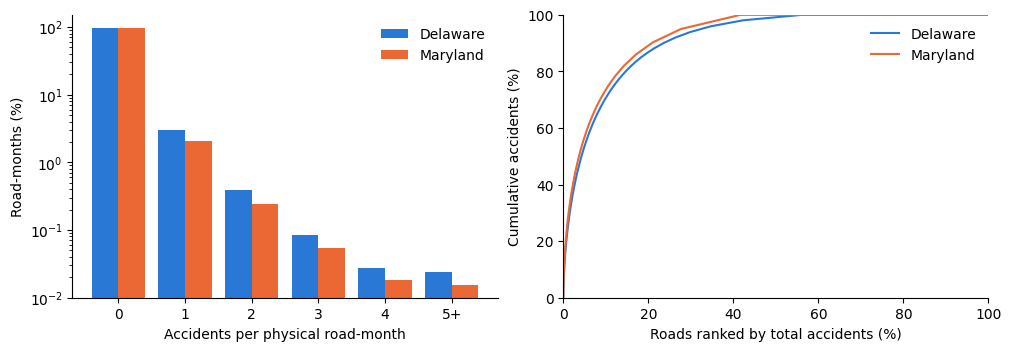

In [6]:
display(distribution[['Road-months', 'Zero accidents (%)', 'Mean count']].style.format({
    'Road-months': '{:,.0f}', 'Zero accidents (%)': '{:.2f}', 'Mean count': '{:.4f}',
}))
fig = plot_risk_profile(data)
plt.show()


*Figure 2. Accident-count distribution and retrospective concentration across physical roads.* The logarithmic axis makes infrequent positive counts visible. Training-period neighbour-risk correlations are 0.538 in Delaware and 0.556 in Maryland. These associations motivate investigation of connected-road information, while shared traffic exposure and road characteristics provide alternative explanations for the spatial dependence.


### Spatial exploration of training accidents

Interactive map A displays recorded accident concentrations during the training years: **2009–2012 in Delaware** and **2015–2017 in Maryland**. State, month and period controls support inspection of recurring locations and surrounding network structure. Counts are unadjusted for exposure and should not be interpreted as causal safety effects.

The display combines a fixed random background with roads having high training-period accident totals. Summary cards cover the full road population, while the displayed subset supports detailed inspection. Straight endpoint connections approximate road geometry. Validation and test labels do not determine which roads are displayed.


In [7]:
from src.visualization.risk_map import show_risk_map, list_prediction_exports

SHOW_INTERACTIVE_MAPS = True
MAP_MAX_ROADS = 1500  # Display budget per state; summary cards still cover all roads.
MAP_OUTPUT_DIR = PROJECT_DIR / 'results' / 'visualizations'
if SHOW_INTERACTIVE_MAPS:
    eda_map_path = show_risk_map(
        PROJECT_DIR, max_roads=MAP_MAX_ROADS, mode='eda',
        data_dir=DATA_DIR, results_dir=PROJECT_DIR / 'results', state_codes=STATES,
        output_path=MAP_OUTPUT_DIR / 'road_safety_training_eda.html',
    )


<iframe title="Road Safety Explorer" width="100%" height="860" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<script src="https://cdn.plot.ly/plotly-3.1.0.min.js"></script>
<style>
*{box-sizing:border-box}body{margin:0;background:#f3f6fa;color:#152238;font:14px system-ui,sans-serif}
header{height:86px;background:#101e34;color:white;padding:20px 26px;display:flex;justify-content:space-between;align-items:center}
h1{font-size:23px;margin:0;letter-spacing:-.5px}header p{margin:5px 0;color:#aebed3;font-size:12px}.badge{color:#85e0ce;border:1px solid #355469;padding:7px 12px;border-radius:20px;font-size:11px}
main{display:grid;grid-template-columns:250px 1fr;gap:16px;padding:18px}aside,.card{background:white;border:1px solid #e1e7ef;border-radius:12px}
aside{padding:20px;height:700px}label{display:block;font-size:11px;text-transform:uppercase;letter-spacing:1px;color:#64748b;margin:22px 0 8px}label:first-child{margin-top:0}
select{width:100%;padding:10px 8px;border:1px solid #d8e0ec;border-radius:7px;background:white;color:#1e293b;font-size:12px}button{border:1px solid #d8e0ec;background:white;border-radius:7px;padding:9px;cursor:pointer;color:#334155}
.nav{display:flex;gap:8px;margin-top:9px}.nav button{flex:1}.note{font-size:11px;color:#64748b;line-height:1.7;margin-top:24px}.stats{display:grid;grid-template-columns:repeat(3,1fr);gap:12px;margin-bottom:12px}.stat{padding:15px 18px}.stat span{display:block;color:#64748b;font-size:11px}.stat strong{display:block;font-size:24px;margin-top:5px;font-weight:650}.maphead{display:flex;justify-content:space-between;padding:16px 18px;border-bottom:1px solid #edf1f6}.maphead b{font-size:15px}.maphead span{font-size:11px;color:#64748b}#map{height:520px}.foot{padding:10px 18px;font-size:11px;color:#64748b;line-height:1.6}#status{color:#b45309;padding-top:8px} @media(max-width:750px){main{grid-template-columns:1fr}aside{height:auto}.stats{gap:5px}.stat strong{font-size:18px}}
</style></head><body>
<header><div><h1 id="appTitle">Road Safety Explorer</h1><p id="appSubtitle">Historical accidents and baseline model predictions</p></div><div class="badge">CS5284 · GROUP 01</div></header>
<main><aside><label>State</label><select id="state"></select><label>Basemap</label><select id="basemap"><option value="carto-darkmatter">Dark · high contrast</option><option value="carto-positron">Light · minimal</option><option value="open-street-map">Street detail</option></select><label>Map layer</label><select id="view"><option value="observed">Recorded accidents</option><option value="predicted">Model prediction</option><option value="error">Prediction error</option></select><label>Model / seed</label><select id="model"></select><label>Aggregation</label><select id="aggregation"><option value="monthly">Monthly</option><option value="quarterly">Quarterly</option><option value="yearly">Yearly</option></select><label>Period</label><select id="month"></select><div class="nav"><button id="prev">← Previous</button><button id="next">Next →</button></div><label>Road details</label><div id="details" class="note">Hover over a road to inspect its values.</div><div class="note">Historical layers cover the retained data period. Predictions cover exported test months only. Opposite directions are combined into physical-road proxies.</div></aside>
<section><div class="stats"><div class="card stat"><span>RECORDED ACCIDENTS</span><strong id="total">—</strong></div><div class="card stat"><span>ROADS WITH ACCIDENTS</span><strong id="positive">—</strong></div><div class="card stat"><span id="thirdLabel">MODEL</span><strong id="third">—</strong></div></div><div class="card"><div class="maphead"><b id="title">Accident map</b><span id="period"></span></div><div id="map"></div><div class="foot" id="foot"></div></div><div id="status"></div></section></main>
<script>
const DATA={"DE":{"dates":["2009-01","2009-02","2009-03","2009-04","2009-05","2009-06","2009-07","2009-08","2009-09","2009-10","2009-11","2009

*Interactive map A. Spatial distribution of training-period accidents.* The standalone HTML accompanying the notebook supports interactive exploration; map rendering requires internet access for external plotting resources and basemap tiles.


### Feature availability and OSM enrichment

Weather missingness varies by variable and state, ranging from **38.8–67.7%** in Delaware and **61.5–74.3%** in Maryland, with coverage also changing over time. Only **3.16%** and **1.40%** of physical roads, respectively, have a finite AADT observation in any supplied year. These gaps motivate missingness indicators and limit exposure-adjusted interpretation of feature associations.


In [8]:
weather_missing = audit['weather_missingness']['Missing (%)'].unstack('State')
display(weather_missing.style.format('{:.1f}').set_caption('Table 3. Missing weather observations (%), across all usable node-months.'))
# Inspect audit['checks'] for the complete integrity report.


State,Delaware,Maryland
Feature,,
Air pressure,67.7,74.3
Maximum temperature,38.8,61.5
Mean temperature,42.7,61.7
Minimum temperature,38.8,61.5
Precipitation,50.5,69.0
Wind speed,46.6,69.7


For Delaware, **89.6%** of directed road rows match an OSM road, including **85.1%** through exact matching. These percentages measure coverage, not matching accuracy. Table 4 distinguishes raw tag coverage from accident-weighted coverage: tagged roads account for a disproportionate share of accidents and are therefore not representative of the network. Missing tags are treated as unknown; a mapped zero for a control does not establish its real-world absence.


In [9]:
from src.osm.report import (
    load_evidence, feature_coverage, feature_groups, score_summary,
    metric_changes, plot_osm_comparison,
)

# Read extracted saved displays; never rebuild OSM or train during report rendering.
# Source hashes are checked so changed notebooks cannot silently reuse stale evidence.
osm_evidence = load_evidence(PROJECT_DIR)
display(feature_coverage(osm_evidence).style.format('{:.1f}').set_caption(
    'Table 4. Delaware raw OSM tag coverage (%). Road shares use directed rows; accident-weighted shares use recorded accidents.'))

,Directed roads (%),Accident-weighted coverage (%)
Feature,,
Speed limit,13.9,43.8
Lanes,12.6,49.8
Surface,17.3,26.8
Cycleway,2.4,9.0
Sidewalk,1.5,2.3
Lighting,0.6,1.4


## Methodology

### Baseline models and road-level prediction

We compare an MLP with the benchmark's edge-aware GraphSAGE adaptation (Hamilton et al., 2017; Nippani et al., 2023), each with and without fixed Node2Vec embeddings (Grover & Leskovec, 2016). GraphSAGE produces intersection representations through message passing; the MLP omits this graph encoder. A shared road-level predictor combines endpoint representations with road attributes. Monthly inputs include weather and available traffic; structural inputs include coordinates, degree and approximate betweenness. Classification and regression use separate task-specific models. The OSM experiment evaluates GraphSAGE classification in Delaware.

### OSM feature construction and matching

A dated OSM extract supplied by Geofabrik (n.d.) is filtered into roads, tagged control points and nearby places, then converted into projected tables using OSMnx (Boeing, 2025). The pipeline corrects swapped latitude/longitude column names in the benchmark inputs and checks node ordering against road lengths. Matching thresholds are methodological choices of this study. Benchmark nodes first match by OSM identifier within a 25 m coordinate tolerance, otherwise by nearest node within 20 m. Directed roads use exact, reverse and then nearest matching. Nearest matches require midpoint distance within 30 m and an OSM-to-benchmark length ratio of 0.6–1.6. Unmatched roads remain in the prediction population.

Five groups provide **58 raw attributes** (Table 5). Tagged controls removed during graph simplification are recovered within 15 m of each road. Nearby-place features use counts within 100, 250, 500 and 1,000 m of the road midpoint and distances to the nearest place. Road shape is benchmark length divided by endpoint straight-line distance. Feature construction does not use accident counts, although a later map snapshot can still introduce temporal mismatch.


In [10]:
display(feature_groups(osm_evidence).style.set_caption(
    'Table 5. Raw feature groups before model encoding; the filled road-character group is an alternative, not an additional raw group.'))

,Description,Raw columns
Group,,
road_character,road character (OSM tags),5
intersection_control,intersection control,14
cycle_pedestrian_lighting,"cycle, pedestrian and lighting tags",3
nearby_places,nearby places,35
road_shape,road shape (curviness),1


### Missing attributes and descriptive checks

Raw values remain separate from estimated values. The pipeline tests gap filling from road type and same-type neighbours using five-fold masking of known physical-road attributes. A method must improve on the state-wide typical value by at least five percentage points and reach at least 60% accuracy, including an estimated accuracy for the missing-road population. Speed predictions count as correct within 5 mph; lane and surface predictions require exact agreement. Under these criteria, **speed limits pass**, while **lanes and surface remain unfilled**. Validation on tagged roads may overestimate performance on genuinely untagged roads.

Feature associations are examined using length/road-type-controlled rate ratios and Poisson regressions with a kilometre-year exposure offset, fitted using statsmodels with `cov_type="HC1"` (statsmodels developers, n.d.). This covariance option does not by itself account for spatial or serial dependence. Sparse tags are analysed on known-value subsets. Training-year repeats assess stability. These analyses describe associations, not causal safety effects or forecast accuracy.

### OSM inputs to the predictive model

The driver validates directed-edge order before appending encoded OSM columns to the baseline road attributes. Counts and distances receive log1p transforms; surface is one-hot encoded; missing and unmatched indicators preserve unavailable information. Lane counts are clipped at eight, sinuosity to 1–5, and standardised values to ±10. Constant columns are removed. The all-group experiment adds **70 encoded columns**, including indicators, to the **25 baseline static road columns**; dynamic traffic columns are retained separately.

The predictive pipeline standardises static OSM attributes and groups rare surface categories over **all graph edges**. This is a transductive static-graph choice, distinct from training-year normalisation of weather and traffic. Raw and gap-filled road-character groups are mutually exclusive; the all-group experiment uses raw tags with missingness indicators.


### Past-only accident-history representation

The history representation comprises six own-road features: last-month count, 3/6/12-month means, twelve-month lag and twelve-month nonzero fraction. Three neighbourhood features describe last-month and three-month mean counts on adjacent roads and the number of neighbours. A coverage indicator records the number of usable prior months. Every dynamic input for target month T ends at T−1. Incomplete windows remain missing, and absent source months are not automatically treated as accident-free.

Opposite-direction counts are summed **before** history construction, and the resulting physical-road features are broadcast to both message-passing directions. Neighbours are distinct physical connections sharing an endpoint, excluding the target road and its reverse. This aligns historical inputs with the prediction target and prevents the unused label direction from being treated as an independent accident-free road.

The descriptive history analysis uses a twelve-month warm-up and is restricted to **2010–2012 Delaware training targets**, leaving 36 eligible months. This past-only cutoff follows the temporal evaluation principle described by Hyndman and Athanasopoulos (2021, Section 5.10). The analysis examines associations with subsequent counts; it does not estimate the incremental performance of a history-enhanced predictive model.


## Experimental Setup

### Training and model selection

Baseline experiments cross **MLP/GraphSAGE × classification/regression × Node2Vec off/on**, giving eight Delaware configurations. Each uses three model seeds (0, 1 and 2), 100 epochs, two width-256 layers, zero dropout and Adam at learning rate 0.001 (Kingma & Ba, 2015). Training samples positive and zero-count roads at a 1:1 ratio; validation and testing include all physical roads. Classification minimises binary cross-entropy. Regression minimises MAE, with negative count predictions clipped to zero at evaluation.

Validation is performed every five epochs and at the final epoch. The checkpoint with highest validation AUROC for classification or lowest validation MAE for regression is evaluated on test. This is checkpoint selection, without early termination of training. Chronological splits are shown in Table 2.

### OSM comparison and evaluation metrics

The GraphSAGE classification experiment crosses **OSM off/on × Node2Vec off/on**. Its Node2Vec control is trained within the comparison and matches the archived baseline at the displayed precision. The no-Node2Vec control is reused from the archived baseline rather than independently retrained. One fixed embedding is shared across model-training seeds.

Primary AUROC is calculated monthly and averaged using positive-road counts as weights. **AP** denotes scikit-learn average precision, rather than trapezoidal area under the precision-recall curve (scikit-learn developers, n.d.). Top-1% precision and recall assess prioritisation. Subgroup AUROC is pooled across road-months and distinguished from the primary monthly metric. Reported spreads are population standard deviations (`ddof=0`) across the three model seeds, rather than confidence intervals.

Feature-group permutation measures fitted-model reliance (Fisher et al., 2019). It does not involve retraining after group removal, so its scores describe sensitivity to perturbed inputs rather than the gain obtainable by adding each group independently. The OSM comparison uses raw attributes; a gap-filled predictive run based on an older feature table is excluded to maintain a consistent feature definition.


## Results and Discussion

### Baseline comparisons

Tables 6–7 compare the eight Delaware configurations across three seeds. Classification is assessed primarily by AUROC and count regression by MAE. Each configuration is reported separately; test performance is not used to select among repeated runs.


In [13]:
from src.reporting import load_training_results, format_training_results, plot_training_history

RESULTS_DIR = PROJECT_DIR / 'results'
training_results = load_training_results(RESULTS_DIR)
if training_results.empty:
    print('No completed ordinary training results are available in', RESULTS_DIR)
else:
    display(format_training_results(training_results, 'classification').style.hide(axis='index').set_caption(
        'Table 6. Classification performance: mean ± SD across model seeds. AP is average precision.'))
    display(format_training_results(training_results, 'regression').style.hide(axis='index').set_caption(
        'Table 7. Count-regression performance: MAE is primary; AUROC evaluates ranking by predicted counts.'))
    # Provenance remains available for inspection alongside each run.
    training_provenance = training_results[['Run', 'Source commit', 'Dirty checkout']]


State,Model,Node2Vec,Seeds,AUROC,AP,Run
DE,graphsage,With,3,0.8743 ± 0.0003,0.2627 ± 0.0013,DE_graphsage_classification_n2v
DE,graphsage,Without,3,0.8461 ± 0.0037,0.2134 ± 0.0024,DE_graphsage_classification_no_n2v
DE,mlp,With,3,0.8780 ± 0.0002,0.2788 ± 0.0016,DE_mlp_classification_n2v
DE,mlp,Without,3,0.8449 ± 0.0008,0.2112 ± 0.0013,DE_mlp_classification_no_n2v


State,Model,Node2Vec,Seeds,MAE,AUROC,Run
DE,graphsage,With,3,0.2070 ± 0.0038,0.8569 ± 0.0025,DE_graphsage_regression_n2v
DE,graphsage,Without,3,0.2316 ± 0.0048,0.8357 ± 0.0013,DE_graphsage_regression_no_n2v
DE,mlp,With,3,0.2201 ± 0.0040,0.8648 ± 0.0011,DE_mlp_regression_n2v
DE,mlp,Without,3,0.2506 ± 0.0022,0.8161 ± 0.0028,DE_mlp_regression_no_n2v


Node2Vec improves both baseline architectures in the Delaware experiments. With Node2Vec, the MLP achieves higher classification AUROC (**0.8780**) than GraphSAGE (**0.8743**), while GraphSAGE achieves lower count-regression MAE (**0.2070**) than the MLP (**0.2201**). The benefit of learned message passing therefore depends on the prediction task. Structural embeddings remain useful even without a learned graph encoder, and the graph model is not uniformly stronger.

The OSM experiment tests incremental improvements to GraphSAGE under its own matched controls. It does not establish superiority over all baseline configurations. GraphSAGE with OSM and Node2Vec reaches AUROC of 0.8772, below the MLP-with-Node2Vec baseline of 0.8780 at the reported precision.


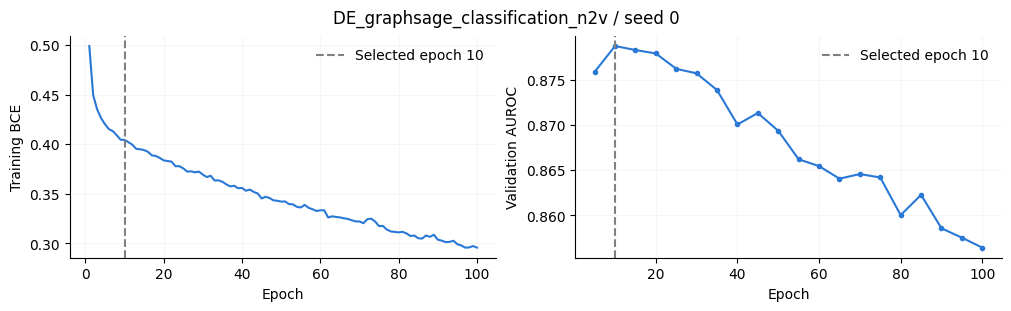

In [14]:
HISTORY_RUN = 'DE_graphsage_classification_n2v'
HISTORY_SEED = 0
if (RESULTS_DIR / HISTORY_RUN / f'seed{HISTORY_SEED}_history.csv').exists():
    fig = plot_training_history(RESULTS_DIR, HISTORY_RUN, HISTORY_SEED)
    plt.show()
else:
    print('Training history unavailable for', HISTORY_RUN)


*Figure 3. Training loss and validation AUROC for GraphSAGE with Node2Vec, seed 0.* The marked checkpoint is selected by validation performance. Training loss uses sampled roads, whereas validation covers all roads; their magnitudes are not directly comparable. Test performance is reserved for final evaluation.


### Incremental predictive value of OSM features

Adding all OSM groups increases mean test AUROC from **0.8743 to 0.8772 with Node2Vec** and from **0.8461 to 0.8713 without Node2Vec** (Table 8). Both comparisons improve in all three seeds. The increases of **+0.0029** and **+0.0252** are absolute AUROC changes, equivalent to 0.29 and 2.52 percentage points. Table 9 reports complementary average-precision and top-risk diagnostics.

The larger improvement without Node2Vec indicates that the incremental value of OSM context depends on the structural information already available to the model. This pattern is consistent with overlapping predictive information, but does not establish that the feature sets encode the same underlying mechanisms.


In [15]:
display(score_summary(osm_evidence).style.format({'AUROC change': '{:+.4f}'}).set_caption(
    'Table 8. Delaware GraphSAGE classification: test AUROC, mean ± SD across three seeds. Values are rounded to the precision of the archived experimental outputs.'))
changes = metric_changes(osm_evidence)
display(changes[changes.Metric.isin(['AP', 'precision@top1%', 'recall@top1%'])].style.format({
    'Baseline': '{:.4f}', 'With OSM': '{:.4f}', 'Change': '{:+.4f}',
}).hide(axis='index').set_caption('Table 9. Supplementary prioritisation metrics from the same selected checkpoints.'))

,Baseline AUROC,With OSM AUROC,AUROC change,Seeds improved
Node2Vec,,,,
Without,0.8461 ± 0.0037,0.8713 ± 0.0008,+0.0252,3/3
With,0.8743 ± 0.0003,0.8772 ± 0.0008,+0.0029,3/3


Node2Vec,Metric,Baseline,With OSM,Change
Without,AP,0.2134,0.2547,+0.0413
Without,precision@top1%,0.3920,0.4450,+0.0530
Without,recall@top1%,0.1048,0.1190,+0.0142
With,AP,0.2627,0.2740,+0.0113
With,precision@top1%,0.4585,0.4714,+0.0130
With,recall@top1%,0.1226,0.1261,+0.0035


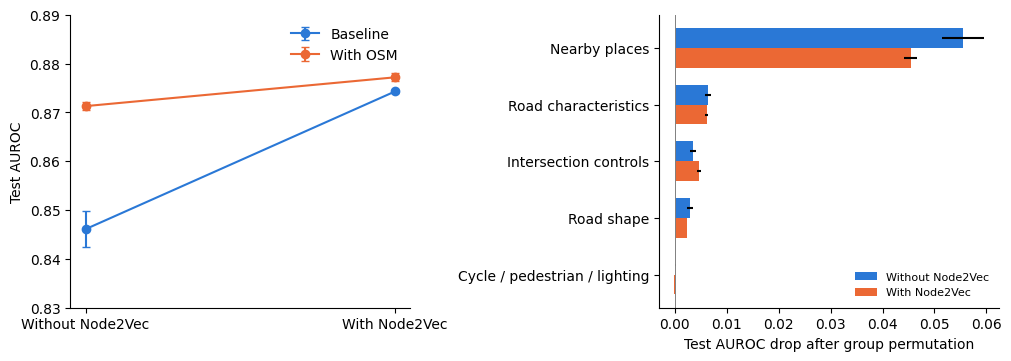

In [16]:
fig = plot_osm_comparison(osm_evidence)
plt.show()

*Figure 4. Left: OSM/Node2Vec comparison with seed standard deviations. Right: test AUROC drop after feature-group permutation; error bars describe variation across seeds.*

### Feature reliance and robustness

Among the OSM groups, nearby places produces the largest permutation drop: **0.0454 with Node2Vec** and **0.0555 without it**. Road characteristics, intersection controls and shape have smaller drops; cycling/pedestrian/lighting tags have near-zero importance in this run. These are fitted-model sensitivities, not additive contributions (Fisher et al., 2019): permuting correlated directed-edge features can produce unrealistic combinations and disrupt consistency between road directions. Low tag coverage also limits interpretation of small drops. Near-zero traffic importance does not establish that traffic exposure is unimportant.

For the Node2Vec comparison, the monthly analysis improves in **57/57 test months**, with a mean change of about +0.0029. Its exploratory whole-month bootstrap interval is **[0.0026, 0.0031]**; resampling ignores serial dependence and does not include training or embedding uncertainty. Pooled subgroup results show a larger AUROC change on motorway roads (+0.0142 across 706 roads) than residential roads (+0.0029 across 44,294 roads), but group prevalence and composition differ.

A spatially blocked ridge probe predicts the top ten Node2Vec components from OSM attributes less accurately than a mean-only reference (held-out weighted R² −0.026; baseline plus OSM −0.028). Those components contain only about 10.8% of embedding variance. The probe therefore provides no direct evidence that the embeddings can be reconstructed from these attributes; the observed 2×2 performance pattern supports only a narrower claim about incremental predictive benefit.


### Historical persistence of accident incidence

Table 10 relates next-month accident incidence to strictly prior three-month accident totals on physical roads. It uses only **2010–2012 Delaware training targets** after the twelve-month warm-up. History construction is checked for target alignment and invariance to changes in target-month and future labels, ensuring that the displayed association does not depend on those labels entering the inputs.

The probability of a next-month accident increases from **2.04%** following zero accidents in the previous three months to **75.80%** following six or more. Mean next-month count increases from **0.0221** to **2.1551** across the same categories. This gradient demonstrates temporal persistence in the training population. It may reflect persistent exposure, road characteristics and other unobserved differences between roads, rather than a causal effect of previous accidents.


In [17]:
import json
from src.history.integration import PhysicalHistory, history_readiness, training_risk_by_history
from src.history.features import run_self_checks

history_data = PhysicalHistory.load(DATA_DIR / 'DE')
history_branch_manifest = json.loads((PROJECT_DIR / 'reports/history_branch_manifest.json').read_text())
history_source_match = (history_data.source_audit['source_sha256'] == history_branch_manifest['source_sha256'])
print('Local accident/graph files match branch exports:', history_source_match)
print('Past-only source self-checks:', run_self_checks())
history_coverage = history_readiness(history_data)  # 36/60/57 with the matched warm-up.
display(training_risk_by_history(history_data).style.format({
    'Road-months': '{:,.0f}', 'Next-month accident probability (%)': '{:.2f}',
    'Mean next-month count': '{:.4f}',
}).hide(axis='index').set_caption(
    'Table 10. Subsequent accident incidence by strictly prior three-month physical-road history (2010–2012 training targets).'))


Prior 3-month accidents,Road-months,Next-month accident probability (%),Mean next-month count
0,"2,163,898",2.04,0.0221
1,"136,650",12.52,0.1475
2,"30,091",24.98,0.3232
3–5,"15,776",42.23,0.6418
6+,"2,657",75.80,2.1551


The history analysis is exploratory: its outcome is an association with subsequent incidence, rather than a measured gain in held-out AUROC or MAE. A predictive comparison would need to account for the shorter training population introduced by the twelve-month warm-up and the availability of accident reports at each forecast origin.


## Limitations

Predictive results are restricted to Delaware, and the OSM comparison evaluates GraphSAGE classification with one fixed structural embedding across three model seeds. The seed standard deviations exclude uncertainty from embedding generation, geographic sampling and temporal dependence. The results consequently support conclusions about these experimental settings rather than geographic transfer or general architectural superiority.

The OSM snapshot dates from 2026, whereas accident labels cover 2009–2022. Later roads and safety interventions can encode information unavailable at the historical forecast origin, including interventions introduced in response to accidents. OSM improvements should therefore be interpreted as retrospective enrichment results rather than evidence of deployable historical forecasting gains. Static attributes are normalised over the full graph, while dynamic inputs use training-year statistics.

Sparse and selective tagging, approximate road matching and missing traffic exposure constrain feature interpretation. A further measurement issue concerns speed limits: the parser treats unit-less values as mph, whereas OSM defines unit-less `maxspeed` values as km/h (OpenStreetMap contributors, n.d.). The impact on the reported scores has not been quantified. Speed-related findings and model gains involving that group require a tag-level audit and sensitivity analysis.

Accident counts and descriptive rate ratios do not establish exposure-adjusted or causal road safety effects. Historical persistence is evaluated descriptively, permutation scores measure fitted-model reliance, and the exploratory bootstrap does not account for serial dependence. Classification calibration is not assessed. These distinctions limit the use of the results for intervention selection or probability-based operational decisions.


## Conclusion

This study evaluates structural embeddings, learned message passing and OSM road context for monthly accident prediction. Node2Vec improves both MLP and GraphSAGE baselines, while the relative value of message passing depends on the task: the MLP leads classification and GraphSAGE leads count regression when embeddings are included. OSM improves GraphSAGE classification under both embedding settings, with a substantially larger increment without Node2Vec. Nearby-place attributes have the greatest measured permutation sensitivity, and prior own-road counts exhibit strong training-period persistence.

These findings support evaluating graph encoders against strong non-message-passing controls and auditing feature availability alongside predictive gains. Retrospective map timing, incomplete exposure information and the unresolved speed-unit discrepancy constrain interpretation. The evidence establishes conditional predictive improvements in Delaware and a descriptive basis for accident-history modelling, rather than causal effects or validated geographic transfer.


## References

Ahmad, N., Wali, B., Khattak, A. J., & Dumbaugh, E. (2021). Built environment, driving errors and violations, and crashes in naturalistic driving environment. Accident Analysis & Prevention, 157, 106158.

Bresson, X., & Laurent, T. (2017). Residual gated graph convnets. arXiv Preprint arXiv:1711.07553.

Dwivedi, V. P., & Bresson, X. (2020). A generalization of transformer networks to graphs. arXiv Preprint arXiv:2012.09699.

Grover, A., & Leskovec, J. (2016). node2vec: Scalable feature learning for networks. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 855–864.

Guerra, A., Gadhiya, V., & Srisurin, P. (2022). Crash prediction on road segments using machine learning methods. ASEAN Engineering Journal, 12(3), 27–37.

Hamilton, W., Ying, Z., & Leskovec, J. (2017). Inductive representation learning on large graphs. Advances in Neural Information Processing Systems, 30.

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. Neural Computation, 9(8), 1735–1780.

Huang, B., & Hooi, B. (2022). Traffic accident prediction using graph neural networks: New datasets and the TRAVEL model. Traffic, 27(29), 31.

Kashifi, M. T., Al-Turki, M., & Sharify, A. W. (2023). Deep hybrid learning framework for spatiotemporal crash prediction using big traffic data. International Journal of Transportation Science and Technology, 12(3), 793–808.

Ma, Z., Zhang, H., Steven, I., Chien, J., Wang, J., & Dong, C. (2017). Predicting expressway crash frequency using a random effect negative binomial model: A case study in China. Accident Analysis & Prevention, 98, 214–222.

Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). Efficient estimation of word representations in vector space. arXiv Preprint arXiv:1301.3781.

Nippani, A., Li, D., Ju, H., Koutsopoulos, H., & Zhang, H. (2023). Graph Neural Networks for Road Safety Modeling: Datasets and Evaluations for Accident Analysis. Advances in Neural Information Processing Systems Datasets and Benchmarks Track, 36.

Perozzi, B., Al-Rfou, R., & Skiena, S. (2014). Deepwalk: Online learning of social representations. Proceedings of the 20th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 701–710.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. Advances in Neural Information Processing Systems, 30.

Wijnen, W., & Stipdonk, H. (2016). Social costs of road crashes: An international analysis. Accident Analysis & Prevention, 94, 97–106.
